## <span style = "color: orange" > Exploratary Data Analysis - AI Powered Food Delivery Intelligence Platform</span>

***

### Basic EDA

In [1]:
# Import necessay libraries

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Dataframe
df = pd.read_csv('food_delivery.csv')

In [3]:
df.head()

,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,...,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating,review,review_sentiment
0,ORD_000001,CUS_00001,RES_0008,DRV_0075,05-10-2025 15:54,05-10-2025,15,Sunday,1,City_C,...,4.4,25,25,29.0,0.0,Completed,NaN,4.6,The food was tasty and the delivery was quick....,Positive
1,ORD_000002,CUS_00013,RES_0024,DRV_0131,01-10-2025 20:00,01-10-2025,20,Wednesday,0,City_A,...,4.7,12,20,24.0,0.0,Completed,NaN,5.0,Very good experience. The food was fresh and d...,Positive
2,ORD_000003,CUS_00049,RES_0013,DRV_0087,07-10-2025 18:24,07-10-2025,18,Tuesday,0,City_C,...,5.0,11,63,72.0,1.0,Completed,NaN,3.6,The order arrived late and I was not happy wit...,Negative
3,ORD_000004,CUS_00007,RES_0001,DRV_0177,30-10-2025 16:54,30-10-2025,16,Thursday,0,City_A,...,4.3,12,23,31.0,1.0,Completed,NaN,4.1,The food quality could be better and the deliv...,Negative
4,ORD_000005,CUS_00325,RES_0029,DRV_0114,15-10-2025 18:34,15-10-2025,18,Wednesday,0,City_B,...,4.0,9,32,42.0,1.0,Completed,NaN,3.9,The food quality could be better and the deliv...,Negative


In [4]:
# Columns
df.columns

Index(['order_id', 'customer_id', 'restaurant_id', 'driver_id',
       'order_timestamp', 'order_date', 'order_hour', 'day_of_week',
       'is_weekend', 'city', 'delivery_area', 'customer_age', 'customer_type',
       'restaurant_type', 'restaurant_primary_category', 'restaurant_rating',
       'items_count', 'subtotal', 'discount_percent', 'tax_amount',
       'service_fee', 'delivery_fee', 'order_total', 'payment_method',
       'tip_amount', 'distance_km', 'weather', 'traffic_level',
       'delivery_partner_experience_months', 'delivery_partner_rating',
       'restaurant_preparation_time_minutes',
       'estimated_delivery_time_minutes', 'actual_delivery_time_minutes',
       'late_delivery', 'order_status', 'cancellation_reason',
       'customer_rating', 'review', 'review_sentiment'],
      dtype='object')

In [5]:
# Removing unwanted columns
remove_cols = ['order_id','customer_id','restaurant_id','driver_id','payment_method','cancellation_reason']
df = df.drop(columns = remove_cols)

# Check shape and columns after removing
print(df.shape)
print(df.columns)

(50000, 33)
Index(['order_timestamp', 'order_date', 'order_hour', 'day_of_week',
       'is_weekend', 'city', 'delivery_area', 'customer_age', 'customer_type',
       'restaurant_type', 'restaurant_primary_category', 'restaurant_rating',
       'items_count', 'subtotal', 'discount_percent', 'tax_amount',
       'service_fee', 'delivery_fee', 'order_total', 'tip_amount',
       'distance_km', 'weather', 'traffic_level',
       'delivery_partner_experience_months', 'delivery_partner_rating',
       'restaurant_preparation_time_minutes',
       'estimated_delivery_time_minutes', 'actual_delivery_time_minutes',
       'late_delivery', 'order_status', 'customer_rating', 'review',
       'review_sentiment'],
      dtype='object')


In [6]:
# Details of dataframe
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 33 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   order_timestamp                      50000 non-null  object 
 1   order_date                           50000 non-null  object 
 2   order_hour                           50000 non-null  int64  
 3   day_of_week                          50000 non-null  object 
 4   is_weekend                           50000 non-null  int64  
 5   city                                 50000 non-null  object 
 6   delivery_area                        50000 non-null  object 
 7   customer_age                         50000 non-null  int64  
 8   customer_type                        50000 non-null  object 
 9   restaurant_type                      50000 non-null  object 
 10  restaurant_primary_category          50000 non-null  object 
 11  restaurant_rating           

In [7]:
# Check duplicates
df.duplicated().sum()

np.int64(0)

In [8]:
# Check missing values
df.isnull().sum()

order_timestamp                          0
order_date                               0
order_hour                               0
day_of_week                              0
is_weekend                               0
city                                     0
delivery_area                            0
customer_age                             0
customer_type                            0
restaurant_type                          0
restaurant_primary_category              0
restaurant_rating                        0
items_count                              0
subtotal                                 0
discount_percent                         0
tax_amount                               0
service_fee                              0
delivery_fee                             0
order_total                              0
tip_amount                             868
distance_km                              0
weather                                  0
traffic_level                            0
delivery_pa

In [9]:
df[df['actual_delivery_time_minutes'].isnull()][
    ['order_status',
     'tip_amount',
     'actual_delivery_time_minutes',
     'late_delivery',
     'customer_rating',
     'review',
     'review_sentiment']
].head(20)

,order_status,tip_amount,actual_delivery_time_minutes,late_delivery,customer_rating,review,review_sentiment
113,Cancelled,NaN,NaN,NaN,NaN,NaN,NaN
185,Cancelled,NaN,NaN,NaN,NaN,NaN,NaN
194,Cancelled,NaN,NaN,NaN,NaN,NaN,NaN
247,Cancelled,NaN,NaN,NaN,NaN,NaN,NaN
257,Cancelled,NaN,NaN,NaN,NaN,NaN,NaN
322,Cancelled,NaN,NaN,NaN,NaN,NaN,NaN
333,Cancelled,NaN,NaN,NaN,NaN,NaN,NaN
344,Cancelled,NaN,NaN,NaN,NaN,NaN,NaN
352,Cancelled,NaN,NaN,NaN,NaN,NaN,NaN
428,Cancelled,NaN,NaN,NaN,NaN,NaN,NaN


The missing values were caused by cancelled orders. Since these values were logically unavailable, we did not use artificial imputation. We handled them according to each task.For cancelled orders, tip amount was set to 0 because no tip was given.

In [10]:
# Replacing the missing values

# For tip amount
df.loc[df['order_status'] == 'Cancelled','tip_amount'] = 0

In [11]:
# Check missing values after replacing
df.isnull().sum()

order_timestamp                          0
order_date                               0
order_hour                               0
day_of_week                              0
is_weekend                               0
city                                     0
delivery_area                            0
customer_age                             0
customer_type                            0
restaurant_type                          0
restaurant_primary_category              0
restaurant_rating                        0
items_count                              0
subtotal                                 0
discount_percent                         0
tax_amount                               0
service_fee                              0
delivery_fee                             0
order_total                              0
tip_amount                               0
distance_km                              0
weather                                  0
traffic_level                            0
delivery_pa

In [12]:
# Convert the datatype of the columns 'order_timestamp' & 'order_date' into datetime
df['order_timestamp'] = pd.to_datetime(df['order_timestamp'], dayfirst = True)
df['order_date'] = pd.to_datetime(df['order_date'], dayfirst = True)

In [13]:
# Check the datatype after converting
df[['order_timestamp', 'order_date']].dtypes

order_timestamp    datetime64[ns]
order_date         datetime64[ns]
dtype: object

In [14]:
# Check again info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 33 columns):
 #   Column                               Non-Null Count  Dtype         
---  ------                               --------------  -----         
 0   order_timestamp                      50000 non-null  datetime64[ns]
 1   order_date                           50000 non-null  datetime64[ns]
 2   order_hour                           50000 non-null  int64         
 3   day_of_week                          50000 non-null  object        
 4   is_weekend                           50000 non-null  int64         
 5   city                                 50000 non-null  object        
 6   delivery_area                        50000 non-null  object        
 7   customer_age                         50000 non-null  int64         
 8   customer_type                        50000 non-null  object        
 9   restaurant_type                      50000 non-null  object        
 10  restaurant

In [15]:
df.head()

,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,delivery_area,customer_age,customer_type,restaurant_type,...,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,customer_rating,review,review_sentiment
0,2025-10-05 15:54:00,2025-10-05,15,Sunday,1,City_C,City_C_Area_3,40,Premium,Casual Dining,...,14,4.4,25,25,29.0,0.0,Completed,4.6,The food was tasty and the delivery was quick....,Positive
1,2025-10-01 20:00:00,2025-10-01,20,Wednesday,0,City_A,City_A_Area_1,19,Regular,Cafe,...,44,4.7,12,20,24.0,0.0,Completed,5.0,Very good experience. The food was fresh and d...,Positive
2,2025-10-07 18:24:00,2025-10-07,18,Tuesday,0,City_C,City_C_Area_3,26,Regular,Fast Food,...,1,5.0,11,63,72.0,1.0,Completed,3.6,The order arrived late and I was not happy wit...,Negative
3,2025-10-30 16:54:00,2025-10-30,16,Thursday,0,City_A,City_A_Area_1,18,New,Fast Food,...,50,4.3,12,23,31.0,1.0,Completed,4.1,The food quality could be better and the deliv...,Negative
4,2025-10-15 18:34:00,2025-10-15,18,Wednesday,0,City_B,City_B_Area_6,20,Regular,Casual Dining,...,21,4.0,9,32,42.0,1.0,Completed,3.9,The food quality could be better and the deliv...,Negative


In [16]:
# Splitting categorical and numerical columns
numerical_col = df.select_dtypes(include = ['int','float']).columns
categorical_col = df.select_dtypes(include = ['string','object']).columns

print(numerical_col)
print(categorical_col)

Index(['order_hour', 'is_weekend', 'customer_age', 'restaurant_rating',
       'items_count', 'subtotal', 'discount_percent', 'tax_amount',
       'service_fee', 'delivery_fee', 'order_total', 'tip_amount',
       'distance_km', 'delivery_partner_experience_months',
       'delivery_partner_rating', 'restaurant_preparation_time_minutes',
       'estimated_delivery_time_minutes', 'actual_delivery_time_minutes',
       'late_delivery', 'customer_rating'],
      dtype='object')
Index(['day_of_week', 'city', 'delivery_area', 'customer_type',
       'restaurant_type', 'restaurant_primary_category', 'weather',
       'traffic_level', 'order_status', 'review', 'review_sentiment'],
      dtype='object')


In [17]:
# Numerical columns details
df[numerical_col].describe()

,order_hour,is_weekend,customer_age,restaurant_rating,items_count,subtotal,discount_percent,tax_amount,service_fee,delivery_fee,order_total,tip_amount,distance_km,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,customer_rating
count,50000.000000,50000.00000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.0000,50000.000000,50000.000000,50000.000000,49132.000000,49132.000000,49132.000000
mean,14.465900,0.26712,27.686580,4.207956,2.91002,30.897938,4.495700,4.128796,1.474600,3.075108,38.169501,1.582125,4.730632,29.7332,4.495062,15.549600,30.950580,35.152365,0.365709,4.295946
std,5.231155,0.44246,7.537796,0.450977,2.02907,27.068965,6.430008,3.636275,1.378101,2.299115,31.054669,2.861108,2.780190,17.4052,0.349198,7.360099,12.825519,14.701154,0.481633,0.530947
min,0.000000,0.00000,18.000000,2.800000,1.00000,5.100000,0.000000,0.570000,0.130000,0.000000,4.870000,0.000000,0.800000,1.0000,3.200000,5.000000,8.000000,10.000000,0.000000,1.800000
25%,11.000000,0.00000,21.000000,3.900000,1.00000,13.100000,0.000000,1.730000,0.580000,0.000000,17.430000,0.000000,2.800000,14.0000,4.300000,10.000000,22.000000,25.000000,0.000000,4.000000
50%,14.000000,0.00000,27.000000,4.200000,2.00000,22.825000,0.000000,2.890000,1.040000,3.500000,28.350000,0.000000,4.100000,29.0000,4.500000,14.000000,28.000000,33.000000,0.000000,4.400000
75%,19.000000,1.00000,33.000000,4.600000,4.00000,40.120000,10.000000,5.390000,1.890000,4.500000,48.660000,2.230000,5.900000,44.0000,4.800000,19.000000,37.000000,42.000000,1.000000,4.700000
max,23.000000,1.00000,55.000000,5.000000,10.00000,362.980000,20.000000,50.820000,25.210000,12.000000,443.210000,53.650000,20.000000,60.0000,5.000000,73.000000,128.000000,172.000000,1.000000,5.000000


In [18]:
# Categorical columns details
df[categorical_col].describe()

,day_of_week,city,delivery_area,customer_type,restaurant_type,restaurant_primary_category,weather,traffic_level,order_status,review,review_sentiment
count,50000,50000,50000,50000,50000,50000,50000,50000,50000,49132,49132
unique,7,4,40,3,4,6,4,3,2,1220,3
top,Thursday,City_A,City_A_Area_1,Regular,Fast Food,Burger,Clear,Medium,Completed,The order arrived on time and the food quality...,Positive
freq,8472,19888,2056,25098,27593,16184,28248,19522,49132,263,29469


In [19]:
# Order status value counts
df['order_status'].value_counts()

order_status
Completed    49132
Cancelled      868
Name: count, dtype: int64

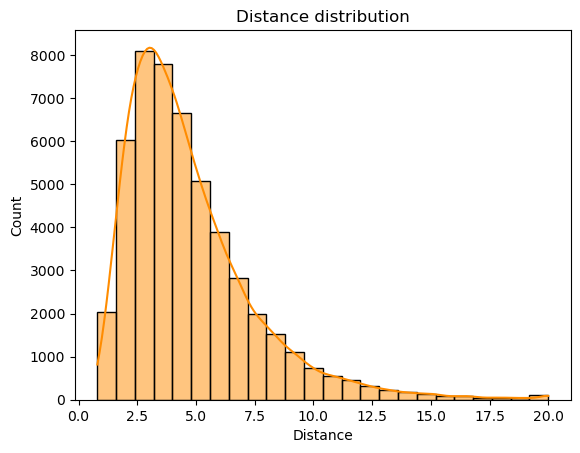

In [20]:
# Distance distribution
sns.histplot(df['distance_km'], bins = 24, kde = True, color = 'darkorange')
plt.title('Distance distribution')
plt.xlabel('Distance')
plt.show()

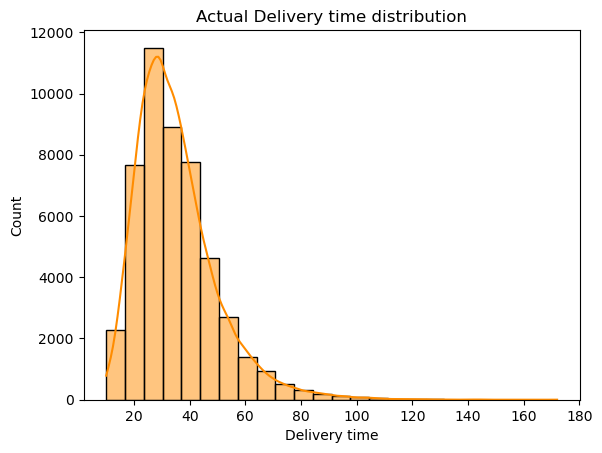

In [21]:
# Actual Delivery time distribution 
sns.histplot(df['actual_delivery_time_minutes'], bins = 24, kde = True, color = 'darkorange')
plt.title('Actual Delivery time distribution')
plt.xlabel('Delivery time')
plt.show()

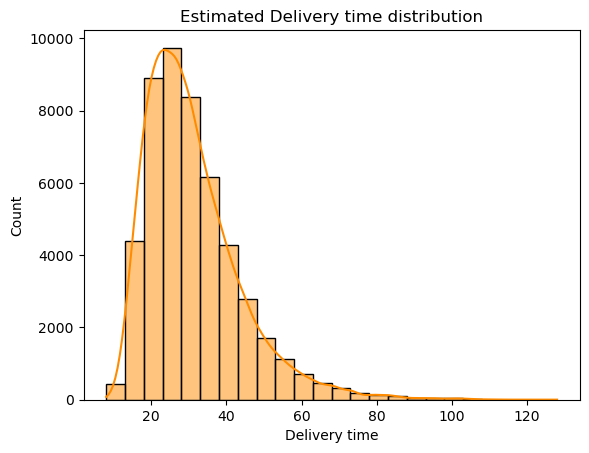

In [22]:
# Estimated Delivery time distribution
sns.histplot(df['estimated_delivery_time_minutes'], bins = 24, kde = True, color = 'darkorange')
plt.title('Estimated Delivery time distribution')
plt.xlabel('Delivery time')
plt.show()

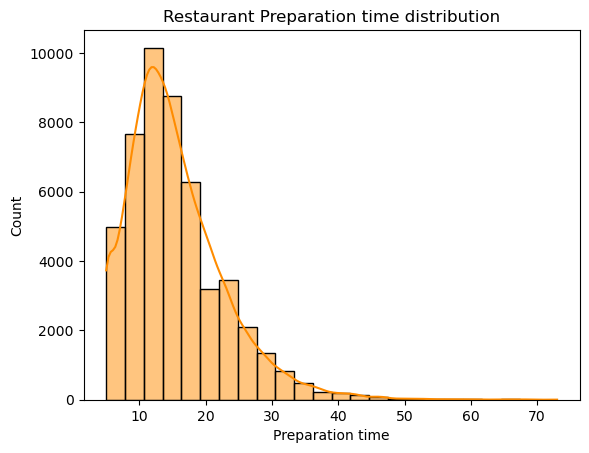

In [23]:
# Restaurant Preparation time distribution  
sns.histplot(df['restaurant_preparation_time_minutes'], bins = 24, kde = True, color = 'darkorange')
plt.title('Restaurant Preparation time distribution')
plt.xlabel('Preparation time')
plt.show()

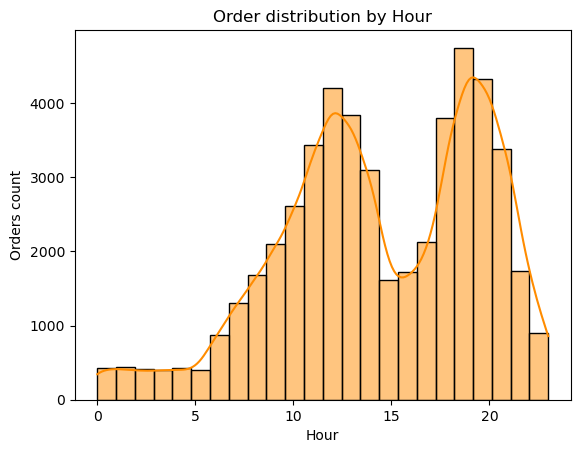

In [24]:
# Order distribution by hour
sns.histplot(df['order_hour'], bins = 24, kde = True, color = 'darkorange')
plt.title('Order distribution by Hour')
plt.xlabel('Hour')
plt.ylabel('Orders count')
plt.show()

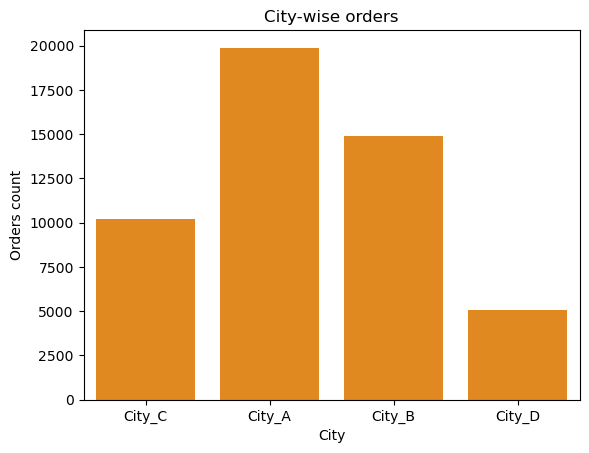

In [25]:
# City-wise orders
sns.countplot(df , x = 'city', color = 'darkorange')
plt.title('City-wise orders')
plt.xlabel('City')
plt.ylabel('Orders count')
plt.show()

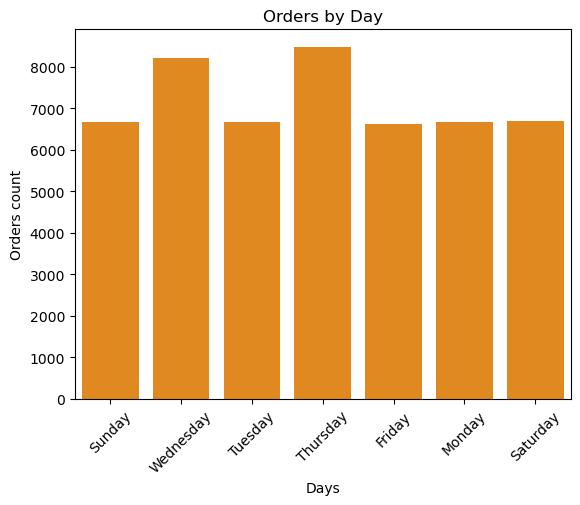

In [26]:
# Orders by Day
sns.countplot(df , x = 'day_of_week', color = 'darkorange')
plt.title('Orders by Day')
plt.xlabel('Days')
plt.ylabel('Orders count')
plt.xticks(rotation = 45)
plt.show()

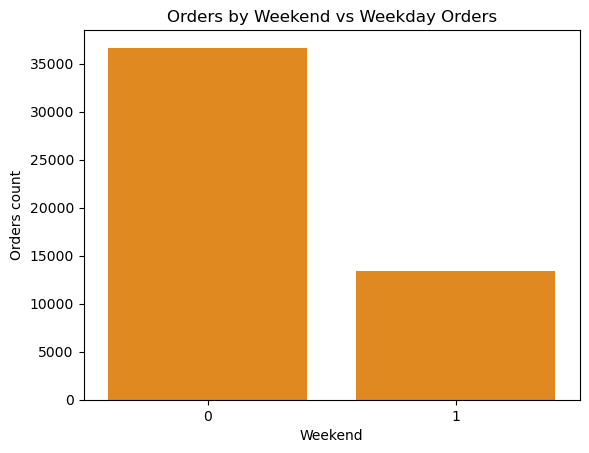

In [27]:
# Orders by Weekend vs Weekday Orders
sns.countplot(df , x = 'is_weekend', color = 'darkorange')
plt.title('Orders by Weekend vs Weekday Orders')
plt.xlabel('Weekend')
plt.ylabel('Orders count')
plt.show()

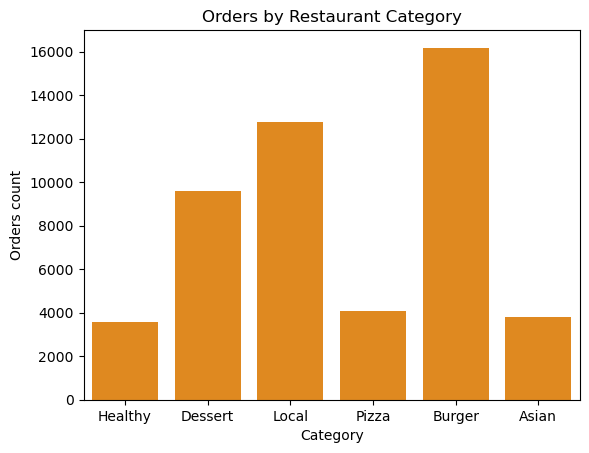

In [28]:
# Orders by Restaurant Category
sns.countplot(df , x = 'restaurant_primary_category', color = 'darkorange')
plt.title('Orders by Restaurant Category')
plt.xlabel('Category')
plt.ylabel('Orders count')
plt.show()

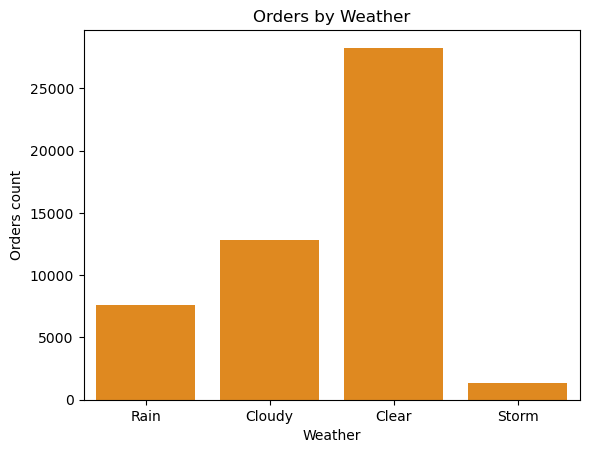

In [29]:
# Orders by Weather
sns.countplot(df , x = 'weather' , color = 'darkorange')
plt.title('Orders by Weather')
plt.xlabel('Weather')
plt.ylabel('Orders count')
plt.show()

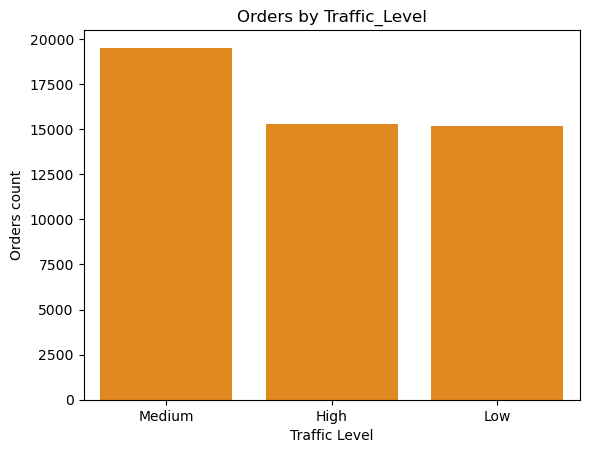

In [30]:
# Orders by Traffic Level
sns.countplot(df , x = 'traffic_level', color = 'darkorange')
plt.title('Orders by Traffic_Level')
plt.xlabel('Traffic Level')
plt.ylabel('Orders count')
plt.show()

In [31]:
outlier_cols = ['customer_age', 'restaurant_rating',
       'items_count', 'subtotal', 'discount_percent', 'tax_amount',
       'service_fee', 'delivery_fee', 'order_total', 'tip_amount',
       'distance_km', 'delivery_partner_experience_months',
       'delivery_partner_rating', 'restaurant_preparation_time_minutes',
       'estimated_delivery_time_minutes', 'actual_delivery_time_minutes',
       'late_delivery', 'customer_rating']

In [32]:
for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    
    print(col, ':', len(outliers))

customer_age : 13
restaurant_rating : 84
items_count : 994
subtotal : 2667
discount_percent : 0
tax_amount : 2594
service_fee : 2863
delivery_fee : 86
order_total : 2613
tip_amount : 4068
distance_km : 2173
delivery_partner_experience_months : 0
delivery_partner_rating : 212
restaurant_preparation_time_minutes : 1468
estimated_delivery_time_minutes : 1758
actual_delivery_time_minutes : 1657
late_delivery : 0
customer_rating : 741


###### IQR method was used to identify potential outliers. Several numerical variables contained observations outside the IQR boundaries. 
###### These values were retained because they can represent genuine variations in food orders, delivery distances, prices, tips, and delivery times.

### Correlation Analysis

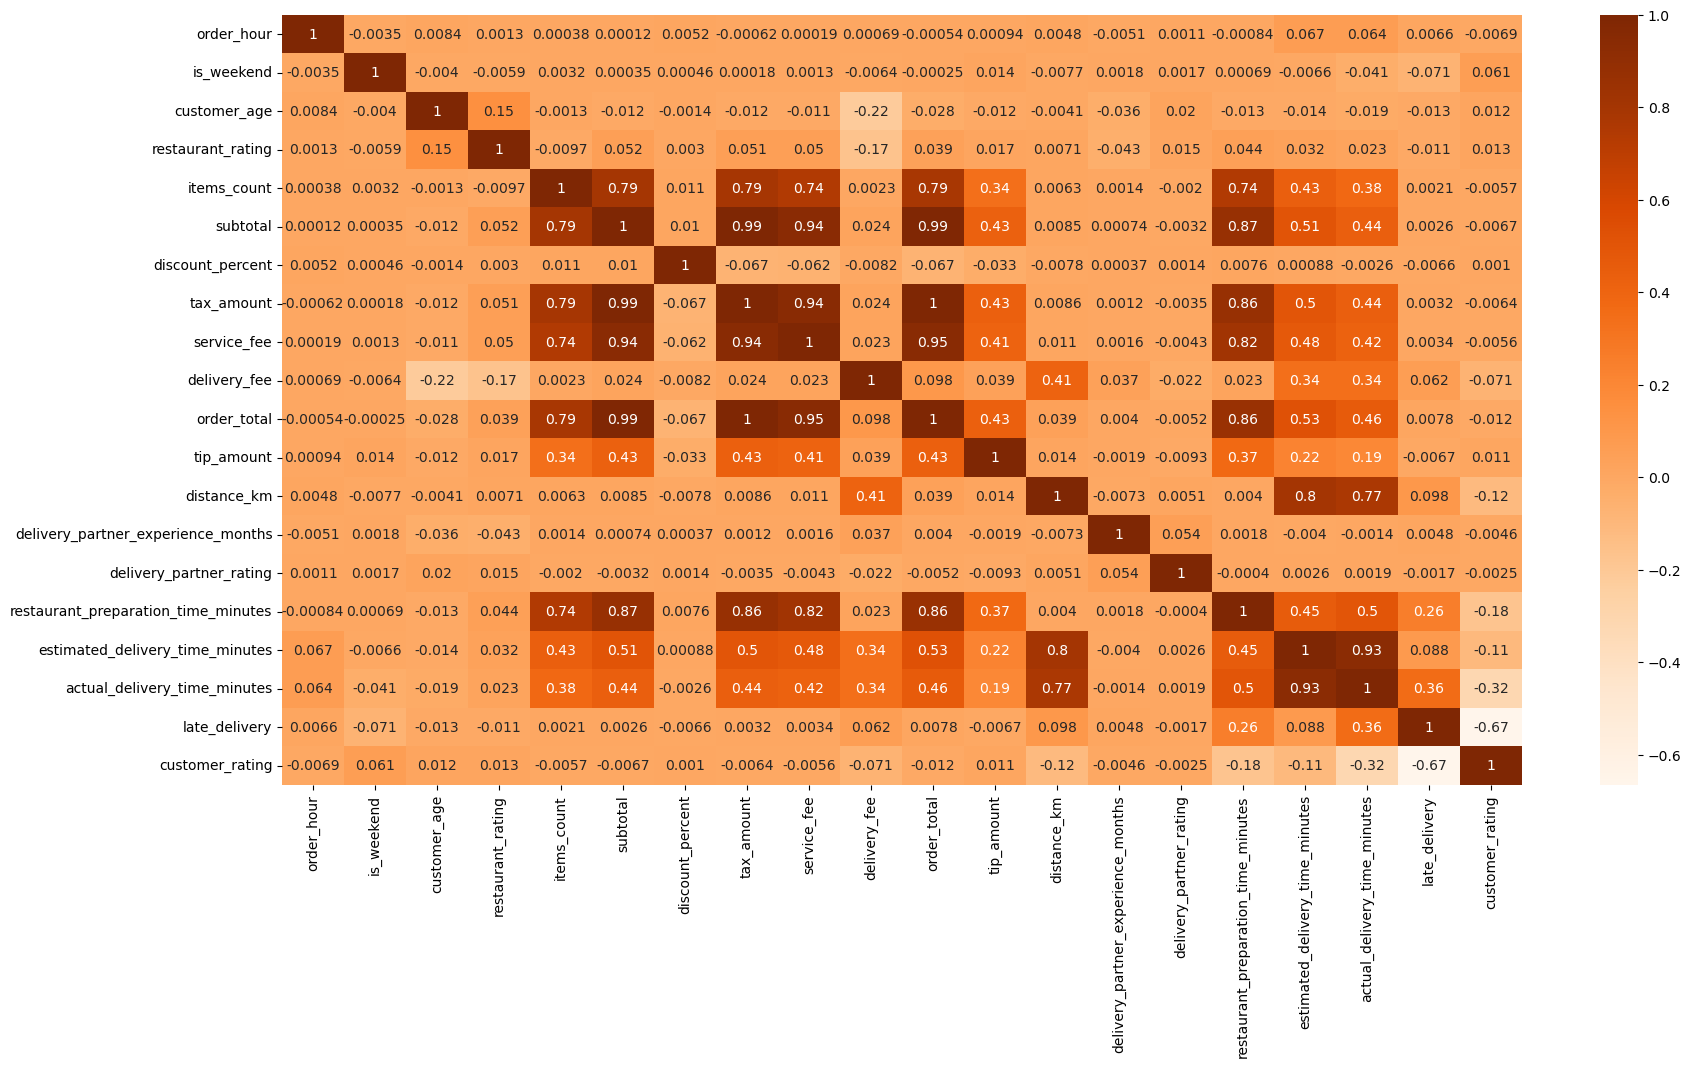

In [33]:
# Correlation of the columns each other
plt.figure(figsize = (20, 10))

corr = df.corr(numeric_only = True)
sns.heatmap(corr, annot = True, cmap='Oranges')
plt.show()

### Demand-wise EDA Analysis

In [34]:
# Adding new column order_count
df['order_count'] = 1

In [35]:
# Calculating the total number of orders per date
daily_demand = (df.groupby('order_date')['order_count'].sum().reset_index())

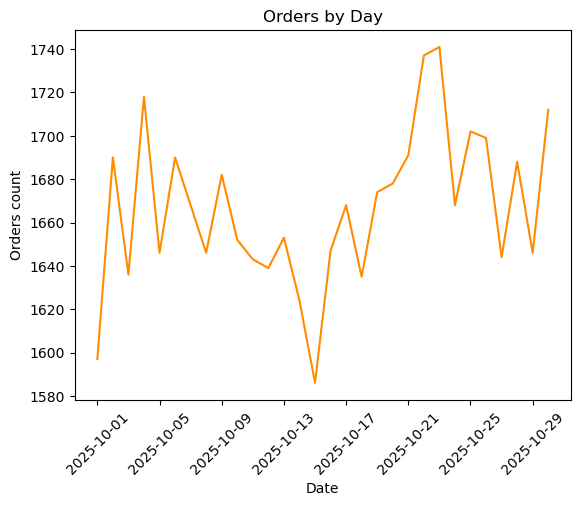

In [36]:
# Orders per date
plt.plot(daily_demand['order_date'], daily_demand['order_count'], color = 'darkorange')
plt.title('Orders by Day')
plt.xlabel('Date')
plt.ylabel('Orders count')
plt.xticks(rotation = 45)
plt.show()

In [37]:
# Calculating the total number of orders per hour
hourly_demand = (df.groupby('order_hour')['order_count'].sum().reset_index())

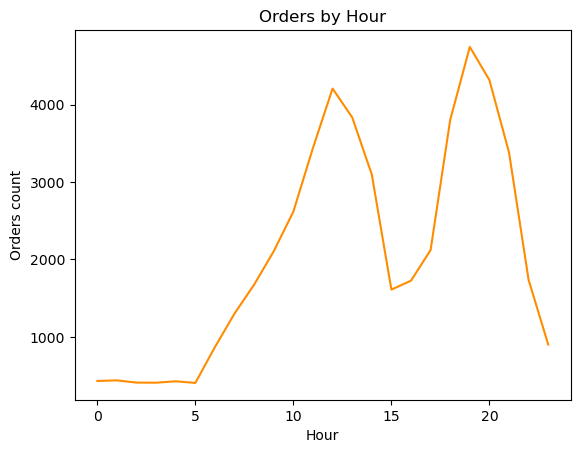

In [38]:
# Orders per hour
plt.plot(hourly_demand['order_hour'], hourly_demand['order_count'], color = 'darkorange')
plt.title('Orders by Hour')
plt.xlabel('Hour')
plt.ylabel('Orders count')
plt.show()

In [39]:
# Calculating the total number of orders per day
day_demand = (df.groupby('day_of_week')['order_count'].sum().reset_index())

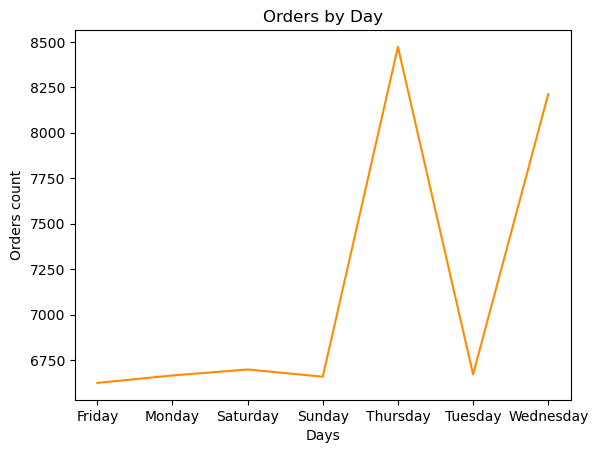

In [40]:
# Orders per day
plt.plot(day_demand['day_of_week'], day_demand['order_count'], color = 'darkorange')
plt.title('Orders by Day')
plt.xlabel('Days')
plt.ylabel('Orders count')
plt.show()

In [41]:
# Calculating the total number of orders per weather
weather_demand = (df.groupby('weather')['order_count'].sum().reset_index())

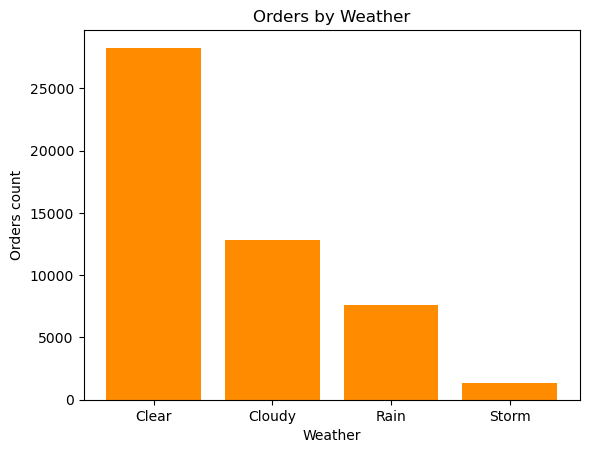

In [42]:
# Orders per weather
plt.bar(weather_demand['weather'], weather_demand['order_count'], color = 'darkorange')
plt.title('Orders by Weather')
plt.xlabel('Weather')
plt.ylabel('Orders count')
plt.show()

In [43]:
# Calculating the total number of orders per traffic
traffic_demand = (df.groupby('traffic_level')['order_count'].sum().reset_index())

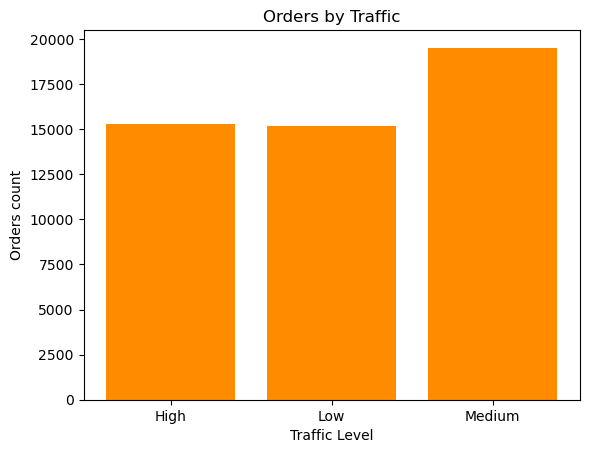

In [44]:
# Orders per traffic
plt.bar(traffic_demand['traffic_level'], traffic_demand['order_count'], color = 'darkorange')
plt.title('Orders by Traffic')
plt.xlabel('Traffic Level')
plt.ylabel('Orders count')
plt.show()

In [45]:
# Calculating the total number of orders per food category
food_demand = (df.groupby('restaurant_primary_category')['order_count'].sum().reset_index())

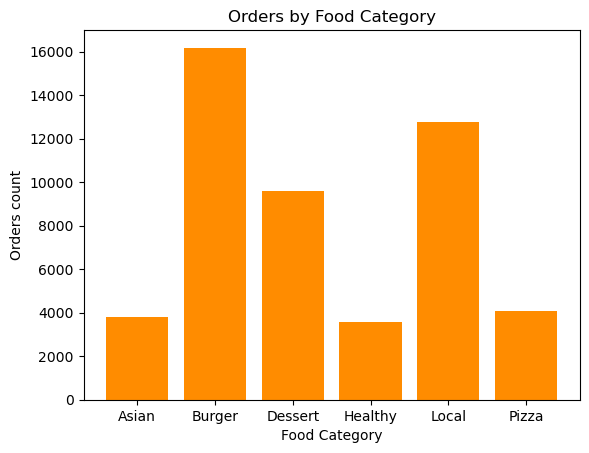

In [46]:
# Orders per traffic
plt.bar(food_demand['restaurant_primary_category'], food_demand['order_count'], color = 'darkorange')
plt.title('Orders by Food Category')
plt.xlabel('Food Category')
plt.ylabel('Orders count')
plt.show()

### Delivery time EDA Analysis

In [47]:
# Filtering orders with available delivery time
delivery_df = df[df['actual_delivery_time_minutes'].notna()].copy()

In [48]:
# Checking the shape of delivery dataframe
delivery_df.shape

(49132, 34)

In [49]:
# Checking the missing values of delivery dataframe
delivery_df['actual_delivery_time_minutes'].isnull().sum()

np.int64(0)

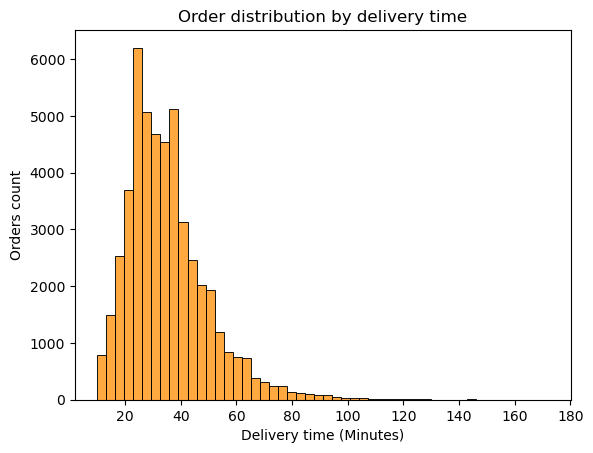

In [50]:
# Order distribution by available delivery time
sns.histplot(delivery_df['actual_delivery_time_minutes'], bins = 50, color = 'darkorange')
plt.title('Order distribution by delivery time')
plt.xlabel('Delivery time (Minutes)')
plt.ylabel('Orders count')
plt.show()

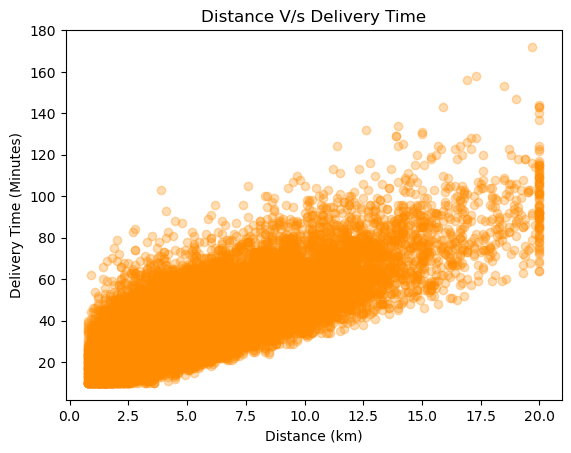

In [51]:
# Distance V/s Delivery Time
plt.scatter(delivery_df['distance_km'], delivery_df['actual_delivery_time_minutes'], alpha = 0.3, color = 'darkorange')
plt.title('Distance V/s Delivery Time')
plt.xlabel('Distance (km)')
plt.ylabel('Delivery Time (Minutes)')
plt.show()

In [52]:
# Calculating the avg.delivery time per traffic
traffic_time = (delivery_df.groupby('traffic_level')['actual_delivery_time_minutes'].mean().reset_index())
traffic_time

,traffic_level,actual_delivery_time_minutes
0,High,39.888079
1,Low,30.593047
2,Medium,35.024275


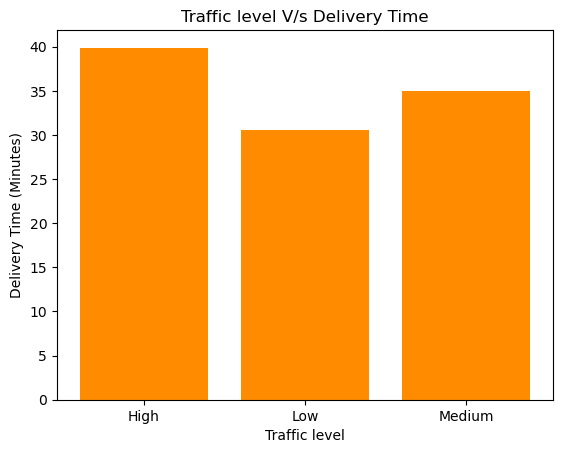

In [53]:
# Traffic level V/s Delivery Time
plt.bar('traffic_level','actual_delivery_time_minutes', data = traffic_time, color = 'darkorange')
plt.title('Traffic level V/s Delivery Time')
plt.xlabel('Traffic level')
plt.ylabel('Delivery Time (Minutes)')
plt.show()

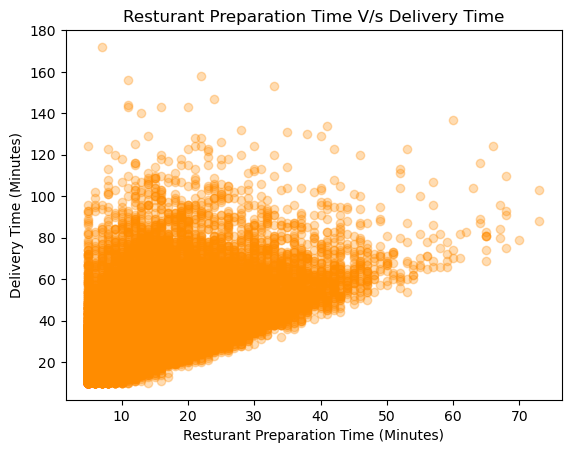

In [54]:
# Resturant Preparation V/s Delivery Time
plt.scatter(delivery_df['restaurant_preparation_time_minutes'], delivery_df['actual_delivery_time_minutes'], alpha = 0.3, color = 'darkorange')
plt.title('Resturant Preparation Time V/s Delivery Time')
plt.xlabel('Resturant Preparation Time (Minutes)')
plt.ylabel('Delivery Time (Minutes)')
plt.show()

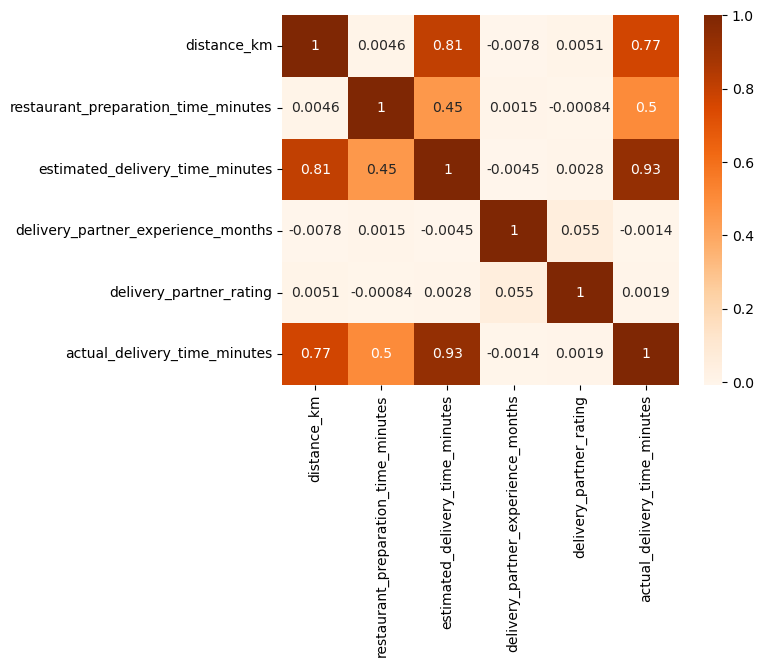

In [55]:
# Delivery related Correlation
delivery_corr = delivery_df[['distance_km','restaurant_preparation_time_minutes','estimated_delivery_time_minutes','delivery_partner_experience_months',
                             'delivery_partner_rating','actual_delivery_time_minutes']].corr()
sns.heatmap(delivery_corr,annot = True, cmap='Oranges')
plt.show()

### Review Sentiment EDA Analysis

In [56]:
# Filtering orders with available reviews
review_df = df[df['review'].notna()].copy()

In [57]:
# Checking the shape of review dataframe
review_df.shape

(49132, 34)

In [58]:
# Checking the missing values of review dataframe
review_df['review'].isnull().sum()

np.int64(0)

In [59]:
review_df.head(10)

,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,delivery_area,customer_age,customer_type,restaurant_type,...,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,customer_rating,review,review_sentiment,order_count
0,2025-10-05 15:54:00,2025-10-05,15,Sunday,1,City_C,City_C_Area_3,40,Premium,Casual Dining,...,4.4,25,25,29.0,0.0,Completed,4.6,The food was tasty and the delivery was quick....,Positive,1
1,2025-10-01 20:00:00,2025-10-01,20,Wednesday,0,City_A,City_A_Area_1,19,Regular,Cafe,...,4.7,12,20,24.0,0.0,Completed,5.0,Very good experience. The food was fresh and d...,Positive,1
2,2025-10-07 18:24:00,2025-10-07,18,Tuesday,0,City_C,City_C_Area_3,26,Regular,Fast Food,...,5.0,11,63,72.0,1.0,Completed,3.6,The order arrived late and I was not happy wit...,Negative,1
3,2025-10-30 16:54:00,2025-10-30,16,Thursday,0,City_A,City_A_Area_1,18,New,Fast Food,...,4.3,12,23,31.0,1.0,Completed,4.1,The food quality could be better and the deliv...,Negative,1
4,2025-10-15 18:34:00,2025-10-15,18,Wednesday,0,City_B,City_B_Area_6,20,Regular,Casual Dining,...,4.0,9,32,42.0,1.0,Completed,3.9,The food quality could be better and the deliv...,Negative,1
5,2025-10-23 14:27:00,2025-10-23,14,Thursday,0,City_B,City_B_Area_6,45,New,Fast Food,...,5.0,12,32,39.0,1.0,Completed,4.0,Poor experience. The food and delivery both ne...,Negative,1
6,2025-10-29 19:20:00,2025-10-29,19,Wednesday,0,City_D,City_D_Area_10,25,New,Fast Food,...,4.8,11,27,31.0,0.0,Completed,4.5,The food was tasty and the delivery was quick....,Positive,1
7,2025-10-26 07:22:00,2025-10-26,7,Sunday,1,City_D,City_D_Area_10,25,Regular,Fast Food,...,4.0,12,20,22.0,0.0,Completed,4.8,Very good experience. The food was fresh and d...,Positive,1
8,2025-10-24 14:28:00,2025-10-24,14,Friday,0,City_C,City_C_Area_4,28,Premium,Cafe,...,4.5,11,37,40.0,0.0,Completed,5.0,Great food and smooth delivery. I enjoyed the ...,Positive,1
9,2025-10-14 20:32:00,2025-10-14,20,Tuesday,0,City_B,City_B_Area_9,28,Regular,Casual Dining,...,4.0,14,25,22.0,0.0,Completed,4.8,The food was tasty and the delivery was quick....,Positive,1


In [60]:
# sentiment value counts
review_df['review_sentiment'].value_counts()

review_sentiment
Positive    29469
Negative    17968
Neutral      1695
Name: count, dtype: int64

In [61]:
# Check duplicate reviews
review_df['review'].duplicated().sum()

np.int64(47912)

In [62]:
review_unique_df = review_df.drop_duplicates(subset='review').copy()

sentiment_count = review_unique_df['review_sentiment'].value_counts()
sentiment_count

review_sentiment
Negative    496
Positive    446
Neutral     278
Name: count, dtype: int64

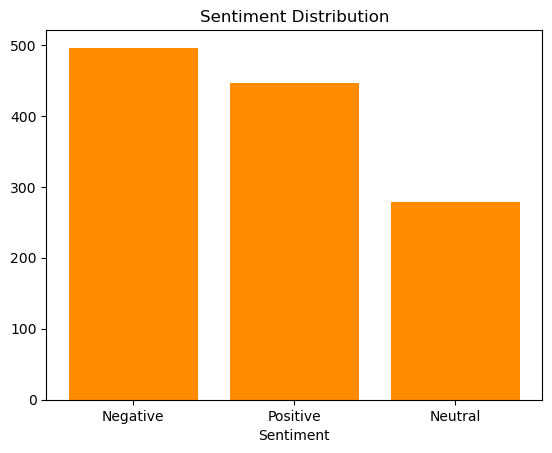

In [63]:
# Sentiment Distribution
plt.bar(sentiment_count.index, sentiment_count.values, color = 'darkorange')
plt.title('Sentiment Distribution')
plt.xlabel('Sentiment')
plt.show()

In [64]:
# Review length analysis
review_unique_df['review_length'] = (review_unique_df['review'].astype(str).str.split().str.len())

In [65]:
review_unique_df['review_length'].describe()

count    1220.000000
mean       16.064754
std         1.805080
min        12.000000
25%        15.000000
50%        16.000000
75%        18.000000
max        19.000000
Name: review_length, dtype: float64

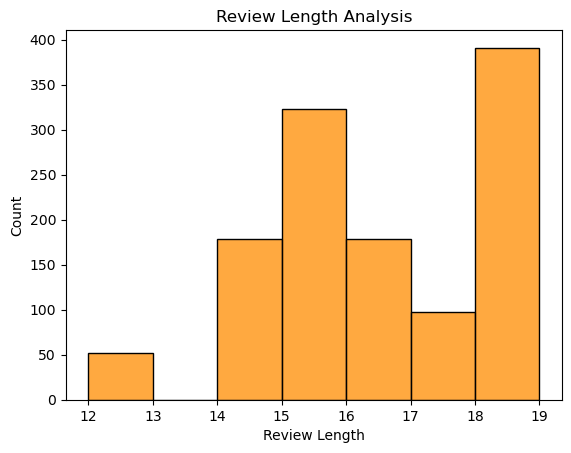

In [66]:
sns.histplot(review_unique_df['review_length'], bins = 7, color = 'darkorange')
plt.title('Review Length Analysis')
plt.xlabel('Review Length')
plt.show()

In [67]:
# Sentiment V/s review length
review_unique_df.groupby('review_sentiment')['review_length'].mean()

review_sentiment
Negative    17.217742
Neutral     14.438849
Positive    15.795964
Name: review_length, dtype: float64

In [69]:
df.to_csv('food_delivery_processed.csv',index = False)

In [70]:
new_df = pd.read_csv('food_delivery_processed.csv')

In [72]:
pd.set_option('display.max_columns', None)
new_df.head()

,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,delivery_area,customer_age,customer_type,restaurant_type,restaurant_primary_category,restaurant_rating,items_count,subtotal,discount_percent,tax_amount,service_fee,delivery_fee,order_total,tip_amount,distance_km,weather,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,customer_rating,review,review_sentiment,order_count
0,2025-10-05 15:54:00,2025-10-05,15,Sunday,1,City_C,City_C_Area_3,40,Premium,Casual Dining,Healthy,4.4,4,64.82,0,9.07,2.40,0.00,76.29,11.36,1.1,Rain,Medium,14,4.4,25,25,29.0,0.0,Completed,4.6,The food was tasty and the delivery was quick....,Positive,1
1,2025-10-01 20:00:00,2025-10-01,20,Wednesday,0,City_A,City_A_Area_1,19,Regular,Cafe,Dessert,4.4,2,13.03,0,1.82,0.84,3.25,18.94,1.09,2.5,Cloudy,High,44,4.7,12,20,24.0,0.0,Completed,5.0,Very good experience. The food was fresh and d...,Positive,1
2,2025-10-07 18:24:00,2025-10-07,18,Tuesday,0,City_C,City_C_Area_3,26,Regular,Fast Food,Dessert,4.8,1,10.12,10,1.28,0.56,7.90,18.85,0.00,11.8,Cloudy,High,1,5.0,11,63,72.0,1.0,Completed,3.6,The order arrived late and I was not happy wit...,Negative,1
3,2025-10-30 16:54:00,2025-10-30,16,Thursday,0,City_A,City_A_Area_1,18,New,Fast Food,Local,3.9,1,8.86,10,1.12,0.40,4.70,14.19,0.00,5.4,Cloudy,Low,50,4.3,12,23,31.0,1.0,Completed,4.1,The food quality could be better and the deliv...,Negative,1
4,2025-10-15 18:34:00,2025-10-15,18,Wednesday,0,City_B,City_B_Area_6,20,Regular,Casual Dining,Pizza,3.5,1,15.08,20,1.69,0.65,5.05,19.45,1.70,6.1,Rain,Medium,21,4.0,9,32,42.0,1.0,Completed,3.9,The food quality could be better and the deliv...,Negative,1


In [73]:
new_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 34 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   order_timestamp                      50000 non-null  object 
 1   order_date                           50000 non-null  object 
 2   order_hour                           50000 non-null  int64  
 3   day_of_week                          50000 non-null  object 
 4   is_weekend                           50000 non-null  int64  
 5   city                                 50000 non-null  object 
 6   delivery_area                        50000 non-null  object 
 7   customer_age                         50000 non-null  int64  
 8   customer_type                        50000 non-null  object 
 9   restaurant_type                      50000 non-null  object 
 10  restaurant_primary_category          50000 non-null  object 
 11  restaurant_rating           

### <span style = "color: green" >  Final EDA Insights</span>

### Dataset Overview

* The dataset contains **50,000 food delivery orders**.
* After removing unnecessary columns such as `order_id`, `customer_id`, `restaurant_id`, `driver_id`, `payment_method`, and `cancellation_reason`, **33 columns** remain.
* The dataset contains information about order timing, customers, restaurants, order amounts, delivery distance, weather, traffic, delivery partners, delivery time, ratings, reviews, and sentiment.

### Missing Value Analysis

* Missing values are mainly present in `actual_delivery_time_minutes`, `late_delivery`, `customer_rating`, `review`, and `review_sentiment`.
* These missing values are related to **cancelled orders**.
* Since these values are not available for cancelled orders, artificial values were not assigned.
* For `tip_amount`, missing values of cancelled orders were replaced with **0**, because cancelled orders do not have a tip.
* The remaining missing values are handled separately according to each prediction task.

### Duplicate Analysis

* After removing the unnecessary columns, the dataset contains no duplicate records.
* 
### Data Type Analysis

* `order_timestamp` and `order_date` were initially stored as object/string values.
* They were converted into **datetime format**.
* This makes the date and time columns easier to use for time-based analysis.
* `order_hour` is already available as a numerical value and can be directly used for hourly demand analysis.

### Categorical Feature Analysis

* Categorical features were analyzed using frequency distributions.
* Important categorical variables include:

  * `city`
  * `restaurant_primary_category`
  * `day_of_week`
  * `weather`
  * `traffic_level`
  * `order_status`
* These features help us understand how orders are distributed across different locations,  food categories, weather conditions, and traffic conditions.

### Numerical Feature Analysis

* Numerical features were analyzed using descriptive statistics and distribution plots.
* Important numerical features include distance, preparation time, estimated delivery time, and actual delivery time.
* These variables provide useful information about delivery distance, and delivery performance.

### Outlier Analysis

* The **IQR method** was used to identify potential outliers.
* Outliers were found in several variables such as `items_count`, `subtotal`, `tax_amount`, `service_fee`, `order_total`, `tip_amount`, `distance_km`, and delivery-time variables.
* These outliers were **not removed**.
* The reason is that these values can represent genuine food-delivery situations.
* For example, a customer may place a large order, a delivery may have a long distance, or an order may take unusually long because of real-world conditions.
* Therefore, removing all these values could remove useful information from the dataset.

### Correlation Analysis

* A correlation heatmap was used to understand relationships between numerical variables.
* Correlation analysis is especially useful for the **delivery-time prediction task**.
* Variables such as delivery distance, restaurant preparation time, estimated delivery time, delivery-partner experience, and delivery-partner rating were compared with actual delivery time.
* This helps identify numerical variables that may be useful for predicting delivery time.

---

## Task-wise EDA Insights

### Demand Prediction 

* For demand prediction, the number of orders was analyzed based on different time-related features.
* A new `order_count` feature was created for demand analysis.
* Orders were aggregated based on `order_date` to understand daily demand.
* Daily order volume changes across different dates.
* Hourly analysis was performed using `order_hour` to understand how order demand changes throughout the day.
* Orders were also analyzed based on the **day of the week**.
* Weekend and weekday order behaviour was also explored using `is_weekend`.
* Demand was further analyzed under different **weather conditions**.
* Traffic-level based order distribution was also checked.
* These analyses show that food delivery demand can vary according to **time and external conditions**.
* Therefore, time-related features such as `order_date`, `order_hour`, `day_of_week`, and `is_weekend`, along with `weather`, `'restaurant_primary_category'` and `traffic_level`, can be considered for the LSTM demand prediction task.

### Delivery Time Prediction 

* For delivery-time prediction, only orders having an available `actual_delivery_time_minutes` value were considered.
* This gives **49,132 completed orders** for the delivery-time analysis.
* The distribution of actual delivery time was analyzed to understand the delivery-time pattern.
* `distance_km` was compared with actual delivery time because delivery distance can affect the time required to complete an order.
* `traffic_level` was also compared with actual delivery time.
* The analysis shows that the average actual delivery time increases from **low traffic to medium traffic and then to high traffic**.
* The average actual delivery time was approximately **30.59 minutes for low traffic, 35.02 minutes for medium traffic, and 39.89 minutes for high traffic**.
* Restaurant preparation time was compared with actual delivery time to understand how preparation affects the overall delivery process.
* Estimated delivery time was also compared with actual delivery time.
* Delivery-partner experience and delivery-partner rating were included in the correlation analysis.
* Therefore, distance, traffic, restaurant preparation time, estimated delivery time, and delivery-partner related features are useful variables to investigate for ANN-based delivery-time prediction.

### Review Sentiment Analysis 

* For sentiment analysis, the available customer reviews were analyzed.
* There are **49,132 reviews** available from completed orders.
* The reviews are classified into **Positive, Negative, and Neutral** sentiments.
* Positive reviews are the largest group, followed by negative reviews and neutral reviews.
* The dataset contains **47,912 repeated review texts**.
* After removing repeated review texts for analysis, there are **1,220 unique reviews**.
* This shows that many review records use the same review text.
* The unique reviews have an average length of approximately **16 words**.
* The review length ranges from approximately **12 to 19 words**.
* Negative reviews have a slightly higher average length than positive and neutral reviews.

